## ⚙️ **Libraries Import**

In [165]:
# Set seed for reproducibility
SEED = 100

import numpy as np

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [166]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        #!ls "/kaggle/input/dataset"
        input_dir = Path('/kaggle/input/datasetcomplete/dataset/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


🌍 Detetected enviroment: KAGGLE
Input directory: /kaggle/input/datasetcomplete/dataset
Output directory: /kaggle/working


In [167]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

## **Constants**

In [168]:
#tutte le costanti utili in un unico posto :)

BATCH_SIZE = 256

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

## ⏳ **Data Loading**

In [169]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE) 
train_images = np.load(INPUT_DIR/'train_images.npy')
train_masks = np.load(INPUT_DIR/'masks_cleaned.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')
train_labels = pd.read_csv(INPUT_DIR/'train_labels.csv')

train_images=train_images.astype('float32')
train_masks=train_masks.astype('float32')
test_images=test_images.astype('float32')
test_masks=test_masks.astype('float32')

print(type(train_images))

# Get class names
class_names = train_labels['label']
#print(class_names)

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")
print(f"Train labels shape: {train_labels.shape}")

<class 'numpy.ndarray'>
Data loaded sucessfully!
Train images shape: (629, 224, 224, 3)
Train masks shape: (629, 224, 224, 1)
Test images shape: (477, 224, 224, 3)
Test masks shape: (477, 224, 224, 1)
Train labels shape: (629, 2)


## 🔎 **Data Analysis**

In [170]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

        sample_index      label
count            629        629
unique           629          4
top     img_0690.png  Luminal B
freq               1        219

--- Unique Labels ---
['Triple negative' 'Luminal B' 'Luminal A' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B          219       34.82
Luminal A          175       27.82
HER2(+)            159       25.28
Triple negative     76       12.08


In [171]:
#number of classes
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [172]:
# Target preparation

# Define the mapping between textual labels and numerical value (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Add new column 'target' to train_labels dataframe
train_labels['target'] = train_labels['label'].map(label_mapping)
target = np.array(train_labels['target']).astype('float32')

# weight = (num_total_training / (num_classes * num_for_class))
# Reindex label_stats to follow the explicit mapping order instead of alphabetical order
ordered_labels = [label for label, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
label_stats_ordered = label_stats.reindex(ordered_labels)
class_weights = (len(train_labels) / (NUM_CLASSES * label_stats_ordered['count'])).astype(np.float32)

# Create list useful later for tensor transformation
class_weights_list = list(class_weights)
print(f"Balanced WEIGHT for each class:\t{class_weights_list}")
print(f"Class order: {ordered_labels}")
class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float32).to(device)

Balanced WEIGHT for each class:	[0.8985714316368103, 0.7180365324020386, 0.9889937043190002, 2.0690789222717285]
Class order: ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']


--- Masking Training Data ---
Processing 629 images...


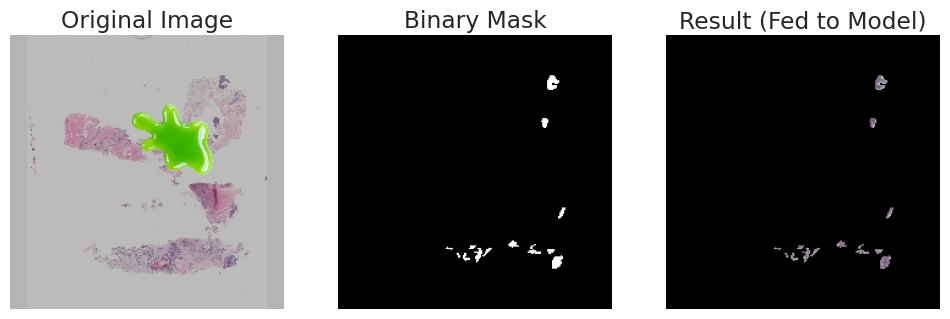

--- Masking Test Data ---
Processing 477 images...


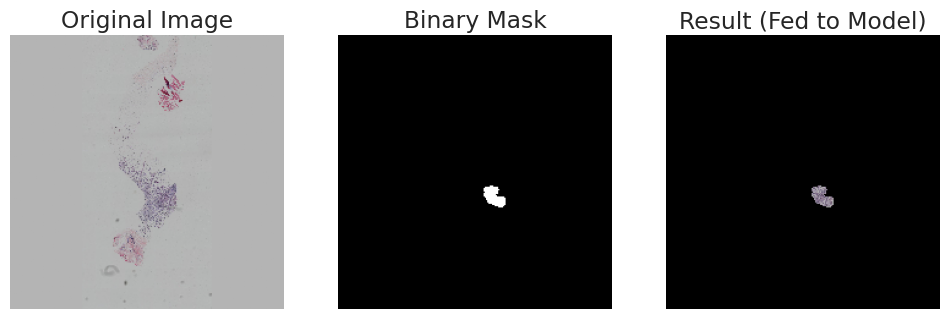

✅ Background removal complete. Images are now cleaner.


In [173]:
# APPLY MASKS TO REMOVE BACKGROUND NOISE
def apply_masks_and_visualize(images, masks, sample_index=0):
    """
    1. Normalizes masks to 0/1.
    2. Multiplies images by masks to black out background.
    3. Visualizes a sample before and after.
    """
    print(f"Processing {len(images)} images...")
    
    # Ensure masks are float32 and normalized to range [0, 1]
    # If the mask is 0-255, divide by 255. If it's already 0-1, leave it.
    masks = masks.astype('float32')
    if masks.max() > 1.0:
        masks /= 255.0
        
    # Thresholding: Ensure mask is strictly binary (0 or 1) to avoid dimming tissue
    # Any value > 0.5 becomes 1, else 0
    masks = (masks > 0.5).astype('float32')

    # SAVE A COPY FOR VISUALIZATION BEFORE MODIFICATION
    sample_img_before = images[sample_index].copy()
    sample_mask = masks[sample_index].copy()

    # APPLY MASK: Element-wise multiplication
    # Broadcasting handles dimensions: (224,224,3) * (224,224,1)
    masked_images = images * masks

    # VISUALIZATION
    plt.figure(figsize=(12, 4))
    
    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(sample_img_before.astype('uint8') if sample_img_before.max() > 1 else sample_img_before)
    plt.title("Original Image")
    plt.axis('off')

    # Mask
    plt.subplot(1, 3, 2)
    plt.imshow(sample_mask.squeeze(), cmap='gray')
    plt.title("Binary Mask")
    plt.axis('off')

    # Result
    plt.subplot(1, 3, 3)
    sample_result = masked_images[sample_index]
    plt.imshow(sample_result.astype('uint8') if sample_result.max() > 1 else sample_result)
    plt.title("Result (Fed to Model)")
    plt.axis('off')
    
    plt.show()
    
    return masked_images

# --- EXECUTE THE MASKING ---

# Apply to Training Data
print("--- Masking Training Data ---")
train_images = apply_masks_and_visualize(train_images, train_masks, sample_index=10)

# Apply to Test Data
print("--- Masking Test Data ---")
test_images = apply_masks_and_visualize(test_images, test_masks, sample_index=10)

print("✅ Background removal complete. Images are now cleaner.")

In [174]:
# SPLIT in TRAIN & VAL

X_train , X_val, y_train, y_val = train_test_split(train_images, target, test_size=0.2, random_state=SEED,  stratify=target)

# Print the shapes of the resulting datasets
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)

Training Data Shape: (503, 224, 224, 3)
Training Label Shape: (503,)
Validation Data Shape: (126, 224, 224, 3)
Validation Label Shape: (126,)


In [175]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [176]:
class MyDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data).permute(0, 3, 1, 2)
        self.labels = torch.from_numpy(labels).squeeze().long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [177]:
# Define geometric augmentations suitable for histology
train_transforms = transforms.Compose([
    #transforms.ToPILImage(), # Convert tensor/numpy to PIL to apply transforms
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=45, translate=(0.2, 0.2)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05),
    #transforms.ToTensor(), # Convert back to tensor
    # Normalization is handled inside MyDataset, so we don't add it here
])

# Convert numpy arrays to customized PyTorch datasets (pairs features with labels)
train_ds = MyDataset(X_train, y_train, augmentation=train_transforms, normalize_imagenet=True) #first without augmentation
val_ds   = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

#train_ds = TensorDataset(torch.from_numpy(X_train).permute(0, 3, 1, 2), torch.from_numpy(y_train).squeeze().long())
#val_ds   = TensorDataset(torch.from_numpy(X_val).permute(0, 3, 1, 2), torch.from_numpy(y_val).squeeze().long())

In [178]:
# Create per-sample weights for the WeightedRandomSampler so that each batch sees a balanced mix
class_weights_cpu = class_weights_tensor.detach().cpu().numpy()
train_sample_weights = torch.from_numpy(class_weights_cpu[y_train.astype(int)]).double()
train_sampler = WeightedRandomSampler(
    weights=train_sample_weights,
    num_samples=len(train_sample_weights),
    replacement=True  # allow minority classes to be sampled with replacement
)

print("WeightedRandomSampler initialized (samples):", len(train_sample_weights))

WeightedRandomSampler initialized (samples): 503


In [179]:
def make_loader(ds, batch_size, shuffle, drop_last, sampler=None):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle if sampler is None else False,  # shuffle handled by sampler when provided
        sampler=sampler,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True if torch.cuda.is_available() else False,  # Faster GPU transfer
        prefetch_factor=8,  # Aumentato da 4 a 8 per buffer più grande
        persistent_workers=True if num_workers > 0 else False,  # Mantiene workers vivi tra epoche
    )

In [180]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, sampler=train_sampler)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [181]:
# print batch shape
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([256, 3, 224, 224])
Labels batch shape: torch.Size([256])


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79b41c140860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^Exception ignored in: ^^<function _MultiProcessingDataLoaderIter.__del__ at 0x79b41c140860>^
^^Traceback (most recent call last):
^  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
^    
self._shutdown_workers()AssertionError
:   File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
can o

## 🧮 **Network Parameters**

In [182]:
# Training parameters
LEARNING_RATE = 0.001
EPOCHS = 300
PATIENCE = 50


# Regularisation
DROPOUT_RATE = 0.2      # Dropout probability (increased from 0.2 to reduce overfitting)
#L1_LAMBDA = 1e-3        # L1 penalty NON È USATA PER ORA
#L2_LAMBDA =  1e-4       # L2 penalty NON È USATA PER ORA

# Set up loss function
#criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
criterion = nn.CrossEntropyLoss()

##  🧠 **Training Functions**

In [183]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name="", scheduler=None):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)
        
        # Step the scheduler if provided (reduce learning rate)
        if scheduler is not None:
            scheduler.step()

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                current_lr = optimizer.param_groups[0]['lr']
                print(f"Epoch {epoch:3d}/{epochs} | LR={current_lr:.6f} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Transfer Learning**

In [184]:
class ModelTransferLearning(nn.Module):
    """EfficientNet-B0 with ImageNet pretrained weights."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # Load weights pretrained on ImageNet
        self.backbone = torchvision.models.efficientnet_b0(
            weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT
        )

        # Freeze the backbone layers (features)
        if freeze_backbone:
            for param in self.backbone.features.parameters():
                param.requires_grad = False

        # Replace classifier (Always trainable)
        in_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate, inplace=True),
            nn.Linear(in_features, num_classes),
        )

    def forward(self, x):
        return self.backbone(x)

In [185]:
# TWO-STAGE TRAINING

# Choose your model 
MODEL_NAME = "EfficientNet"

EXPERIMENT_NAME = f"{MODEL_NAME}_finetuned"

# ----------------------------
# STAGE 1: WARM-UP (Head Only)
# ----------------------------
print(f"🚀 Warming up (Training Classifier Head Only)...")

# Initialize with FROZEN backbone
model = ModelTransferLearning( NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)

# High LR to train the head quickly
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Train for just 10 epochs to stabilize the head
model, history_warmup = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    experiment_name=f"{MODEL_NAME}_warmup",
    patience=PATIENCE,
    verbose=1
)

# ----------------------------
# STAGE 2: FINE-TUNING (Full)
# ----------------------------
print("\n🔓 STAGE 2: Fine-Tuning (Layers 3 & 4)...")

# 1. Load Warmup Weights
model.load_state_dict(torch.load(OUTPUT_DIR / "models" / f"{MODEL_NAME}_warmup_model.pt"))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 20

# Strategy: Freeze everything first, then unfreeze the last few blocks
for param in model.parameters():
    param.requires_grad = False

# The classifier is always trainable
for param in model.backbone.classifier.parameters():
    param.requires_grad = True

# Unfreeze the last 2 blocks of the feature extractor (EfficientNet-B0 has 9 blocks usually)
# Adjust slice index [-2:] to unfreeze more or fewer layers
for block in model.backbone.features[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Check trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

# 6. DIFFERENTIAL LEARNING RATES (Pro Tip)
# We give the Head a higher LR, and the Backbone a lower LR to be gentle.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# 8. Train
model, history_finetune = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS, 
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    patience=PATIENCE,
    experiment_name=EXPERIMENT_NAME,
    verbose=1, 
)

print("✅ Training Complete.")
final_val_f1 = max(history_finetune['val_f1'])
print(f"Best Validation F1: {final_val_f1:.4f}")

🚀 Warming up (Training Classifier Head Only)...
Training 10 epochs...
Epoch   1/10 | LR=0.001000 | Train: Loss=1.4087, F1=0.2259 | Val: Loss=1.4438, F1=0.1544
Epoch   2/10 | LR=0.001000 | Train: Loss=1.3927, F1=0.2624 | Val: Loss=1.4095, F1=0.2297
Epoch   3/10 | LR=0.001000 | Train: Loss=1.3859, F1=0.2613 | Val: Loss=1.3824, F1=0.1828
Epoch   4/10 | LR=0.001000 | Train: Loss=1.3973, F1=0.2576 | Val: Loss=1.3917, F1=0.1184
Epoch   5/10 | LR=0.001000 | Train: Loss=1.3758, F1=0.2800 | Val: Loss=1.4026, F1=0.1643
Epoch   6/10 | LR=0.001000 | Train: Loss=1.3771, F1=0.2896 | Val: Loss=1.4152, F1=0.1911
Epoch   7/10 | LR=0.001000 | Train: Loss=1.3812, F1=0.2803 | Val: Loss=1.4091, F1=0.2256
Epoch   8/10 | LR=0.001000 | Train: Loss=1.3734, F1=0.3144 | Val: Loss=1.3945, F1=0.2336
Epoch   9/10 | LR=0.001000 | Train: Loss=1.3817, F1=0.3031 | Val: Loss=1.3871, F1=0.2418
Epoch  10/10 | LR=0.001000 | Train: Loss=1.3734, F1=0.3036 | Val: Loss=1.3854, F1=0.2510
Best model restored from epoch 10 with v

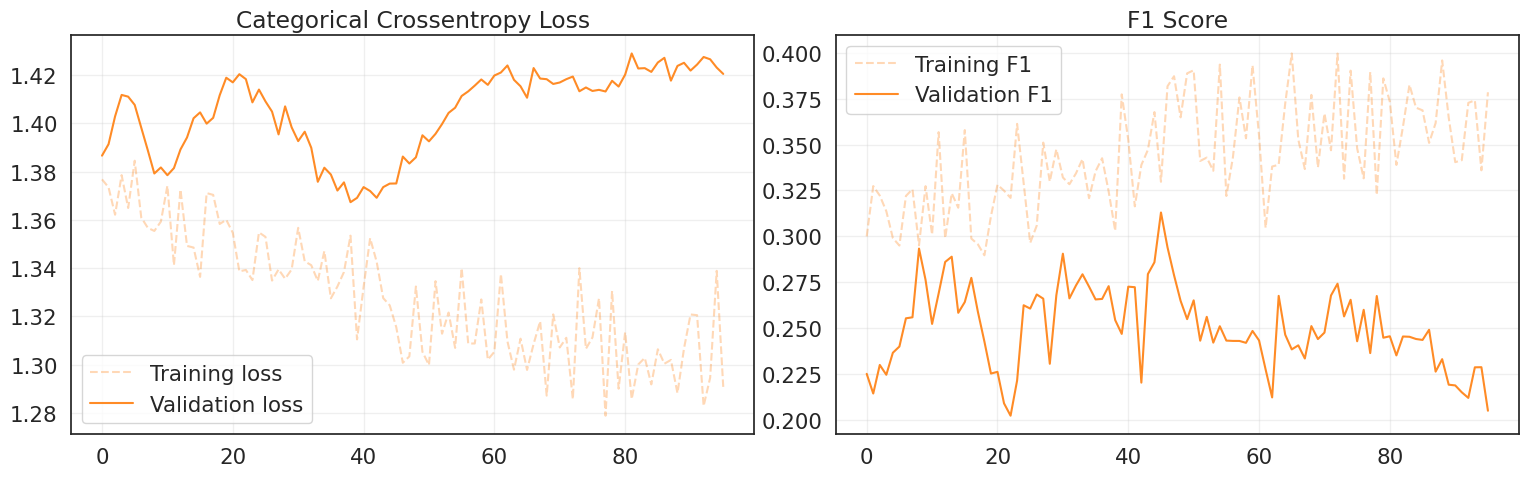

In [186]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(history_finetune['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(history_finetune['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(history_finetune['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(history_finetune['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.2302
Precision over the validation set: 0.2551
Recall over the validation set: 0.2302
F1 score over the validation set: 0.2267
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            45.71%
Luminal B            20.45%
HER2(+)              12.50%
Triple negative      0.00%
-----------------------------------


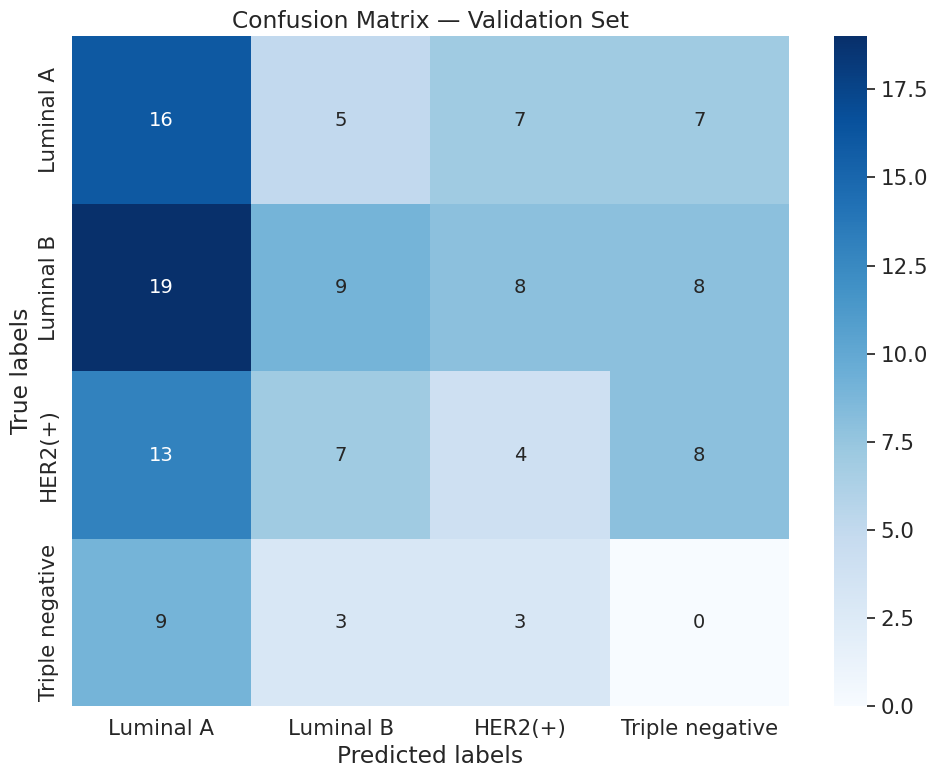

In [187]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🕹️ **Test Inference**

In [188]:
#PREPARE DATA FOR TESTING
# Use MyDataset with ImageNet normalization (no augmentation for test)
test_ds = MyDataset(test_images, np.zeros(len(test_images)), augmentation=None, normalize_imagenet=True)
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [189]:
# Load the  model for inference
best_model = ModelTransferLearning(MODEL_NAME, NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
best_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))
best_model.eval()

print("Model loaded successfully!")

TypeError: ModelTransferLearning.__init__() got multiple values for argument 'freeze_backbone'

In [ ]:
# Collect predictions and ground truth labels
test_preds = []
with torch.no_grad():  # Disable gradient computation for inference
    for batch in test_loader:

        xb = batch[0].to(device)

        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)

# Create CSV SUBMISSION
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

# Ricostruisco il nome delle immagini: i=0 -> "img_0000.png", i=10 -> "img_0010.png"
filenames = [f"img_{i:04d}.png" for i in range(len(test_preds))]
predicted_labels = [target_to_label[p] for p in test_preds]

df_results = pd.DataFrame({
    "sample_index": filenames,
    "label": predicted_labels
})

csv_path = OUTPUT_DIR / 'test_predictions.csv'
df_results.to_csv(csv_path, index=False, header=True)
print(f"✅ test_predictions.csv created and saved successfully in: {csv_path}")